# Analisis Algoritma Strassen Matrix Multiplication

**Notebook tugas individu Algoritma Komputasi — Magister Teknik Informatika**

**Nama:** `Ary Kurnia`  
**NIM:** `D082261011`  

**Tujuan:** mengimplementasikan metode konvensional, Strassen rekursif, dan Strassen hybrid secara mandiri; memeriksa kebenaran; mengukur runtime minimal 5 ukuran dengan 5 pengulangan; membandingkan dengan model kompleksitas teoretis.

> Notebook ini disusun dengan bantuan AI.

## 1. Teori singkat dan contoh manual

Untuk matriks $A,B\in\mathbb{R}^{n\times n}$, perkalian matriks didefinisikan $C_{ij}=\sum_{k=1}^{n}A_{ik}B_{kj}$.

Metode konvensional tiga loop memerlukan $\Theta(n^3)$ operasi. Strassen membagi setiap matriks menjadi empat blok dan melakukan **7** perkalian rekursif alih-alih 8, dengan biaya operasi penjumlahan/pengurangan blok $\Theta(n^2)$:

$$T(n)=7T(n/2)+\Theta(n^2)=\Theta(n^{\log_2 7})\approx\Theta(n^{2.807}).$$

Contoh manual:

$$A=\begin{bmatrix}1&2\\3&4\end{bmatrix},\qquad B=\begin{bmatrix}5&6\\7&8\end{bmatrix}.$$

Dengan $A=\begin{bmatrix}a&b\\c&d\end{bmatrix}$ dan $B=\begin{bmatrix}e&f\\g&h\end{bmatrix}$:

$$\begin{aligned}M_1&=(a+d)(e+h) &M_2&=(c+d)e &M_3&=a(f-h)\\M_4&=d(g-e)&M_5&=(a+b)h&M_6&=(c-a)(e+f)\\M_7&=(b-d)(g+h).&&&&\end{aligned}$$

Kemudian $C_{11}=M_1+M_4-M_5+M_7$, $C_{12}=M_3+M_5$, $C_{21}=M_2+M_4$, dan $C_{22}=M_1-M_2+M_3+M_6$.

Untuk contoh di atas, $(M_1,\ldots,M_7)=(65,35,-2,8,24,22,-30)$ dan $AB=\begin{bmatrix}19&22\\43&50\end{bmatrix}$.

In [11]:
import sys
import platform
from time import perf_counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("CPU:", platform.processor() or "Lihat spesifikasi perangkat secara manual")

Python: 3.12.7
Platform: Linux-7.0.0-38-generic-x86_64-with-glibc2.43
NumPy: 2.5.3
Pandas: 3.0.6
CPU: Lihat spesifikasi perangkat secara manual


## 2. Implementasi dari nol

**Aturan implementasi:** perkalian inti tidak menggunakan `@`, `np.dot`, `np.matmul`, ataupun `np.linalg`. NumPy dipakai untuk penyimpanan array, pemotongan blok, penjumlahan/pengurangan, pembuatan data, dan validasi saja.

Implementasi di bawah menggunakan bilangan bulat `int64` dengan input kecil agar tidak terjadi overflow. Untuk ukuran bukan pangkat dua, kedua matriks ditambahkan nol (*zero padding*) hingga pangkat dua berikutnya.

In [12]:
def perkalian_naive(A, B):
    """Perkalian dua matriks persegi dengan tiga loop, tanpa operasi matmul pustaka."""
    A = np.asarray(A)
    B = np.asarray(B)
    if A.ndim != 2 or B.ndim != 2 or A.shape[1] != B.shape[0]:
        raise ValueError("Dimensi A dan B harus cocok untuk perkalian")
    n, k = A.shape
    _, m = B.shape
    C = np.zeros((n, m), dtype=np.result_type(A.dtype, B.dtype))
    for i in range(n):
        for j in range(m):
            total = 0
            for t in range(k):
                total += A[i, t] * B[t, j]
            C[i, j] = total
    return C

In [13]:
def _strassen_rekursif(A, B, ambang=1):
    """Inti rekursif Strassen. Input: matriks persegi, sama ukuran, pangkat dua."""
    n = A.shape[0]
    if n <= ambang:
        return perkalian_naive(A, B)

    h = n // 2
    a, b, c, d = A[:h, :h], A[:h, h:], A[h:, :h], A[h:, h:]
    e, f, g, h2 = B[:h, :h], B[:h, h:], B[h:, :h], B[h:, h:]

    # Tujuh perkalian Strassen.
    m1 = _strassen_rekursif(a + d, e + h2, ambang)
    m2 = _strassen_rekursif(c + d, e, ambang)
    m3 = _strassen_rekursif(a, f - h2, ambang)
    m4 = _strassen_rekursif(d, g - e, ambang)
    m5 = _strassen_rekursif(a + b, h2, ambang)
    m6 = _strassen_rekursif(c - a, e + f, ambang)
    m7 = _strassen_rekursif(b - d, g + h2, ambang)

    c11 = m1 + m4 - m5 + m7
    c12 = m3 + m5
    c21 = m2 + m4
    c22 = m1 - m2 + m3 + m6
    C = np.empty((n, n), dtype=np.result_type(A.dtype, B.dtype))
    C[:h, :h], C[:h, h:] = c11, c12
    C[h:, :h], C[h:, h:] = c21, c22
    return C


def perkalian_strassen(A, B, ambang=1):
    """Strassen dengan padding; ambang=1 untuk murni, ambang>1 untuk hybrid."""
    A, B = np.asarray(A), np.asarray(B)
    if A.ndim != 2 or B.ndim != 2 or A.shape[1] != B.shape[0]:
        raise ValueError("Dimensi A dan B harus cocok untuk perkalian")
    if not isinstance(ambang, int) or ambang < 1:
        raise ValueError("ambang harus integer >= 1")
    if 0 in A.shape or 0 in B.shape:
        raise ValueError("Dimensi nol tidak didukung oleh notebook ini")
    n, k = A.shape
    _, m = B.shape
    ukuran = 1 << (max(n, k, m) - 1).bit_length()
    dtype = np.result_type(A.dtype, B.dtype)
    A_pad = np.zeros((ukuran, ukuran), dtype=dtype)
    B_pad = np.zeros((ukuran, ukuran), dtype=dtype)
    A_pad[:n, :k] = A
    B_pad[:k, :m] = B
    C_pad = _strassen_rekursif(A_pad, B_pad, ambang=ambang)
    return C_pad[:n, :m].copy()


def perkalian_hybrid(A, B, ambang=32):
    """Hybrid: Strassen di level atas, metode tiga loop pada submasalah kecil."""
    return perkalian_strassen(A, B, ambang=ambang)

### Pseudocode ringkas

```text
STRASSEN(A, B, ambang):
    Jika ukuran(A) <= ambang: kembalikan NAIVE(A, B)
    Bagi A dan B ke empat blok berukuran n/2 x n/2
    Hitung M1,...,M7 menggunakan tujuh panggilan STRASSEN
    Susun C11, C12, C21, C22 dari kombinasi M1,...,M7
    Kembalikan matriks C
```

**Sketsa bukti kebenaran:** Basis: untuk $n\leq$ ambang, tiga loop menghitung definisi $C_{ij}$. Langkah induksi: anggap ketujuh panggilan rekursif menghasilkan produk submatriks yang benar. Substitusi identitas aljabar Strassen menghasilkan $C_{11}=ae+bg$, $C_{12}=af+bh$, $C_{21}=ce+dg$, $C_{22}=cf+dh$ (untuk blok). Jadi matriks gabungan sama dengan $AB$. Padding tidak mengubah hasil pada blok dimensi asal karena elemen tambahan nol.

## 3. Uji kebenaran (minimal tiga kasus kecil yang dapat diperiksa manual)

Tes 1: matriks 2×2 umum. Tes 2: matriks identitas 4×4. Tes 3: perkalian dengan matriks nol 4×4. Tambahan: ukuran 3×3 dan dimensi persegi panjang untuk memeriksa padding.

In [14]:
uji = [
    ("2x2 manual", np.array([[1, 2], [3, 4]], dtype=np.int64),
     np.array([[5, 6], [7, 8]], dtype=np.int64),
     np.array([[19, 22], [43, 50]], dtype=np.int64)),
    ("identitas 4x4", np.array([[2, 1, 0, 4], [1, 3, 5, 2],
                                 [0, 2, 1, 1], [4, 0, 3, 2]], dtype=np.int64),
     np.eye(4, dtype=np.int64),
     np.array([[2, 1, 0, 4], [1, 3, 5, 2], [0, 2, 1, 1], [4, 0, 3, 2]], dtype=np.int64)),
    ("nol 4x4", np.arange(1, 17, dtype=np.int64).reshape(4, 4),
     np.zeros((4, 4), dtype=np.int64), np.zeros((4, 4), dtype=np.int64)),
]
for nama, A, B, ekspektasi in uji:
    for metode in (perkalian_naive, perkalian_strassen, perkalian_hybrid):
        hasil = metode(A, B)
        assert np.array_equal(hasil, ekspektasi), f"GAGAL: {nama}, {metode.__name__}"
    print("LULUS:", nama, "| hasil =", ekspektasi.tolist())

A3 = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]], dtype=np.int64)
B3 = np.array([[2, 0, 1], [1, 3, 2], [0, 1, 4]], dtype=np.int64)
assert np.array_equal(perkalian_strassen(A3, B3), A3 @ B3)
A_rect = np.arange(1, 7, dtype=np.int64).reshape(2, 3)
B_rect = np.arange(1, 13, dtype=np.int64).reshape(3, 4)
assert np.array_equal(perkalian_strassen(A_rect, B_rect), A_rect @ B_rect)
print("LULUS: 3x3 (padding) dan 2x3 × 3x4 (padding)")

LULUS: 2x2 manual | hasil = [[19, 22], [43, 50]]
LULUS: identitas 4x4 | hasil = [[2, 1, 0, 4], [1, 3, 5, 2], [0, 2, 1, 1], [4, 0, 3, 2]]
LULUS: nol 4x4 | hasil = [[0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]]
LULUS: 3x3 (padding) dan 2x3 × 3x4 (padding)


## 4. Desain eksperimen

- **Variabel bebas:** ukuran matriks $n$.
- **Variabel terikat:** waktu eksekusi dalam detik.
- **Metode:** naive tiga loop, Strassen rekursif murni (ambang 1), Strassen hybrid (ambang 32).
- **Ukuran:** 8, 16, 32, 64, 128 (lima ukuran).
- **Pengulangan:** 5 kali setiap ukuran dan metode. Waktu per pengulangan dicatat untuk menghitung rerata dan simpangan baku sampel (`ddof=1`).
- **Keadilan uji:** gunakan pasangan matriks sama di setiap metode dan ukuran; periksa hasil terhadap NumPy `@` di luar blok pengukuran; lakukan satu pemanasan per metode.
- **Batasan:** pengukuran dipengaruhi CPU, OS, beban latar, overhead interpreter Python, dan alokasi array. Karena bilangan kecil, operasi `int64` diasumsikan tidak overflow.

**Catatan:** NumPy `@` hanya digunakan sebagai oracle kebenaran, bukan inti algoritma; jangan menyamakan performa fungsi teroptimasi C/BLAS dengan kode Python tiga loop.

Strassen murni dapat memakan waktu lebih lama untuk $n=128$. Bila komputer lambat, biarkan selesai atau turunkan ukuran setelah mencatat dan membenarkan revisi desain eksperimen.

In [15]:
UKURAN = [8, 16, 32, 64, 128]
PENGULANGAN = 5
SEED = 2026
AMBANG_HYBRID = 32

metode_uji = {
    "Naive": perkalian_naive,
    "Strassen murni": lambda A, B: perkalian_strassen(A, B, ambang=1),
    "Strassen hybrid": lambda A, B: perkalian_hybrid(A, B, ambang=AMBANG_HYBRID),
}

rng = np.random.default_rng(SEED)
data_matriks = {
    n: (rng.integers(-4, 5, size=(n, n), dtype=np.int64),
        rng.integers(-4, 5, size=(n, n), dtype=np.int64))
    for n in UKURAN
}
print("Konfigurasi:", UKURAN, "pengulangan:", PENGULANGAN,
      "seed:", SEED, "ambang hybrid:", AMBANG_HYBRID)

Konfigurasi: [8, 16, 32, 64, 128] pengulangan: 5 seed: 2026 ambang hybrid: 32


In [16]:
catatan = []
for n in UKURAN:
    A, B = data_matriks[n]
    jawaban = A @ B  # HANYA validasi di luar timing
    print(f"Menjalankan ukuran n={n} ...")
    for nama, fungsi in metode_uji.items():
        assert np.array_equal(fungsi(A, B), jawaban), f"Pemanasan gagal: {nama}, {n}"
        for ulang in range(1, PENGULANGAN + 1):
            mulai = perf_counter()
            hasil = fungsi(A, B)
            durasi = perf_counter() - mulai
            assert np.array_equal(hasil, jawaban), f"Hasil salah: {nama}, {n}, ulang {ulang}"
            catatan.append({"n": n, "metode": nama, "ulangan": ulang,
                            "waktu_detik": durasi})

hasil_mentah = pd.DataFrame(catatan)
ringkasan = (hasil_mentah.groupby(["n", "metode"], as_index=False)
             .agg(rata_rata_detik=("waktu_detik", "mean"),
                  simpangan_baku_detik=("waktu_detik", lambda x: x.std(ddof=1)),
                  jumlah_pengulangan=("waktu_detik", "size")))
print("Total percobaan:", len(hasil_mentah))
display(ringkasan.round(6))

Menjalankan ukuran n=8 ...
Menjalankan ukuran n=16 ...
Menjalankan ukuran n=32 ...
Menjalankan ukuran n=64 ...
Menjalankan ukuran n=128 ...
Total percobaan: 75


,n,metode,rata_rata_detik,simpangan_baku_detik,jumlah_pengulangan
0,8,Naive,0.000329,0.000035,5
1,8,Strassen hybrid,0.000342,0.000041,5
2,8,Strassen murni,0.003536,0.000528,5
3,16,Naive,0.002576,0.000248,5
4,16,Strassen hybrid,0.002163,0.000081,5
5,16,Strassen murni,0.021323,0.000617,5
6,32,Naive,0.015208,0.001566,5
7,32,Strassen hybrid,0.016035,0.001925,5
8,32,Strassen murni,0.146809,0.011258,5
9,64,Naive,0.121544,0.004252,5


## 5. Grafik hasil pengukuran versus kurva kompleksitas teori

Kurva teoretis dinormalisasi ke waktu terukur pada ukuran terkecil **untuk metode masing-masing** agar dapat dibandingkan bentuk pertumbuhannya. Ini **bukan** prediksi waktu absolut atau hasil regresi. Garis naive menggunakan $n^3$, Strassen menggunakan $n^{\log_2 7}$.

Plot menggunakan skala logaritmik sumbu-Y sehingga rentang waktu yang lebar tetap terbaca.

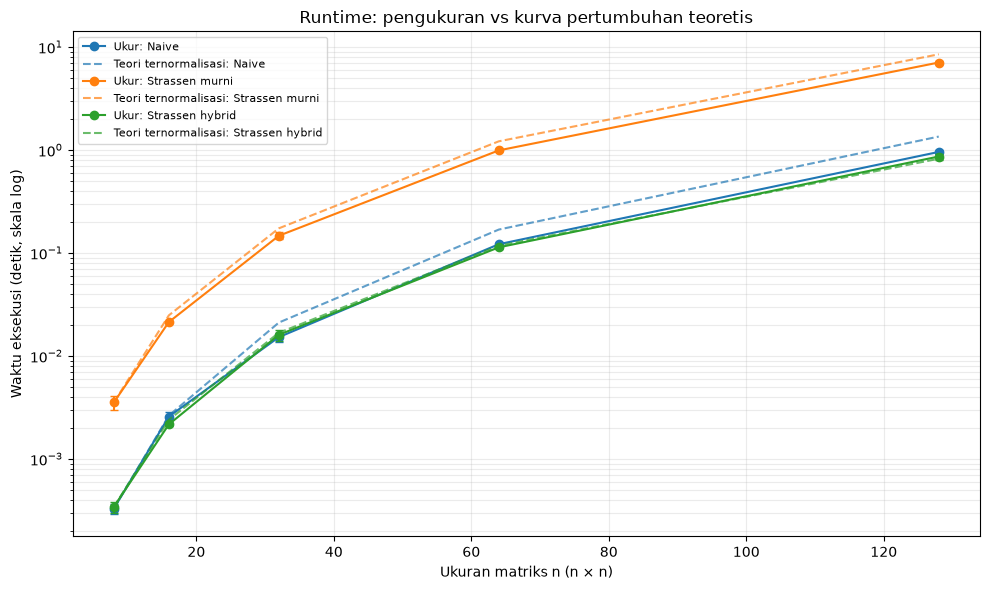

In [17]:
plt.figure(figsize=(10, 6))
pangkat = {"Naive": 3.0, "Strassen murni": np.log2(7),
           "Strassen hybrid": np.log2(7)}
for nama in metode_uji:
    subset = ringkasan[ringkasan["metode"] == nama].sort_values("n")
    x = subset["n"].to_numpy(dtype=float)
    y = subset["rata_rata_detik"].to_numpy(dtype=float)
    e = subset["simpangan_baku_detik"].to_numpy(dtype=float)
    (garis,) = plt.plot(x, y, marker="o", label=f"Ukur: {nama}")
    plt.errorbar(x, y, yerr=e, fmt="none", capsize=3, color=garis.get_color())
    teori = y[0] * (x / x[0]) ** pangkat[nama]
    plt.plot(x, teori, linestyle="--", color=garis.get_color(),
             alpha=0.7, label=f"Teori ternormalisasi: {nama}")
plt.xlabel("Ukuran matriks n (n × n)")
plt.ylabel("Waktu eksekusi (detik, skala log)")
plt.yscale("log")
plt.title("Runtime: pengukuran vs kurva pertumbuhan teoretis")
plt.grid(True, which="both", alpha=0.25)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Analisis hasil dan interpretasi

Diskusikan hal-hal berikut berdasarkan **data yang benar-benar keluar dari perangkatmu**:

1. Pada ukuran berapa Strassen murni mengalahkan naive (jika ada)? Apakah hybrid lebih cepat?
2. Apakah bentuk tren sesuai dengan $n^3$ dan $n^{2.807}$? Jelaskan bahwa overhead dan konstanta tidak dicerminkan Big-O.
3. Apakah simpangan baku cukup besar sehingga perbedaan runtime tidak meyakinkan? Jangan mengklaim signifikansi statistik tanpa analisis tambahan.
4. Mengapa ambang hybrid dapat mengurangi overhead rekursi?
5. Apa keterbatasan eksperimen (ukuran kecil, implementasi Python, cache dan memori, satu mesin, bilangan kecil)?

Gunakan sel berikut sebagai bahan tabel *speedup* (nilai di atas 1 berarti hybrid lebih cepat daripada naive).

In [18]:
tabel_waktu = ringkasan.pivot(index="n", columns="metode", values="rata_rata_detik")
tabel_waktu["speedup_naive_terhadap_hybrid"] = (
    tabel_waktu["Naive"] / tabel_waktu["Strassen hybrid"]
)
display(tabel_waktu.round(6))

metode,Naive,Strassen hybrid,Strassen murni,speedup_naive_terhadap_hybrid
n,,,,
8,0.000329,0.000342,0.003536,0.962014
16,0.002576,0.002163,0.021323,1.191036
32,0.015208,0.016035,0.146809,0.948408
64,0.121544,0.113322,0.990350,1.072550
128,0.956781,0.863591,7.065704,1.107911


## 7. Ekspor hasil untuk laporan

Berkas akan tersimpan di folder aktif notebook setelah sel dijalankan. Sisipkan tabel dan gambar ke BAB IV, lalu tulis uraian interpretasi dengan kata-katamu sendiri.

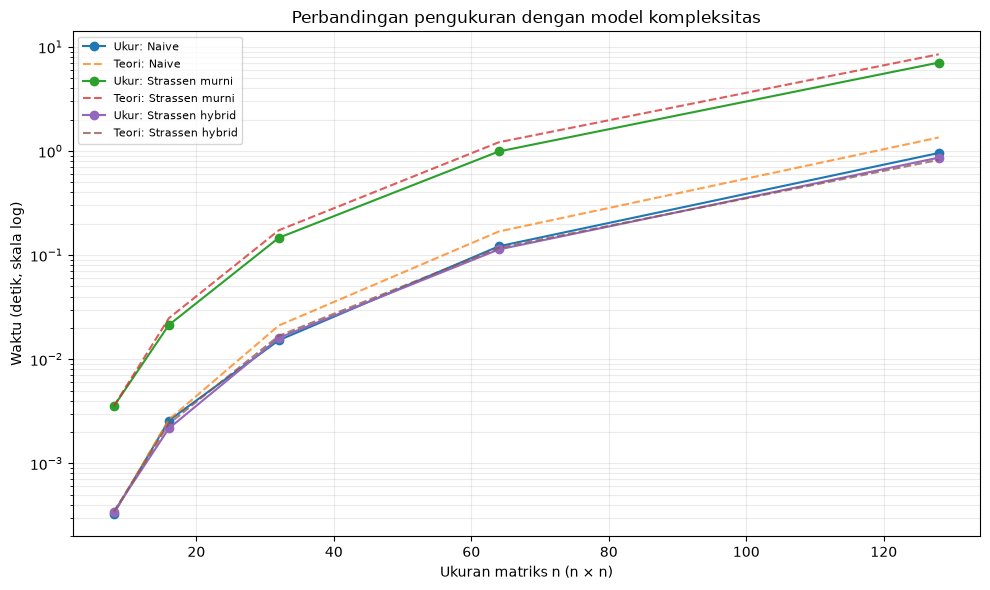

File dibuat: strassen_waktu_mentah.csv, strassen_ringkasan.csv, strassen_perbandingan_teori.png


In [19]:
hasil_mentah.to_csv("strassen_waktu_mentah.csv", index=False)
ringkasan.to_csv("strassen_ringkasan.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
for nama in metode_uji:
    subset = ringkasan[ringkasan["metode"] == nama].sort_values("n")
    x = subset["n"].to_numpy(dtype=float)
    y = subset["rata_rata_detik"].to_numpy(dtype=float)
    ax.plot(x, y, marker="o", label=f"Ukur: {nama}")
    ax.plot(x, y[0] * (x / x[0]) ** pangkat[nama], "--", alpha=0.75,
            label=f"Teori: {nama}")
ax.set(xlabel="Ukuran matriks n (n × n)", ylabel="Waktu (detik, skala log)",
       title="Perbandingan pengukuran dengan model kompleksitas")
ax.set_yscale("log")
ax.grid(alpha=0.25, which="both")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("strassen_perbandingan_teori.png", dpi=180)
plt.show()
print("File dibuat: strassen_waktu_mentah.csv, strassen_ringkasan.csv, strassen_perbandingan_teori.png")

## 8. Kesimpulan dan tindak lanjut

**Isi setelah eksperimen:** rumuskan (a) kebenaran hasil perkalian, (b) tren pertumbuhan runtime, (c) trade-off rekursi versus overhead, (d) relevansi hybrid, (e) keterbatasan penelitian.

**Catatan pengembangan:** eksperimen lanjutan dapat membandingkan beberapa nilai ambang, menambahkan profiler memori, mencoba dimensi tidak berpangkat dua, serta membandingkan dengan NumPy `@` sebagai pembanding pustaka yang sangat teroptimasi (dengan interpretasi yang adil).

### Referensi awal yang perlu diverifikasi dan dilengkapi

- Strassen, V. (1969). *Gaussian Elimination is Not Optimal*. Numerische Mathematik, 13, 354–356.
- Cormen, T. H., Leiserson, C. E., Rivest, R. L., & Stein, C. *Introduction to Algorithms* (edisi 4), bahasan perkalian matriks Strassen dan Master Theorem.

**Untuk laporan final:** minimal delapan sumber dan sedikitnya tiga artikel jurnal/konferensi dalam lima tahun terakhir; cari serta verifikasi metadata dan relevansi sumber sendiri. Catat versi pustaka dan perangkat uji dari sel awal notebook.